# 05 — Comparaison de modèles de segmentation | Panier Vert

**Objectif :** comparer trois approches de clustering sur les **mêmes clients et les mêmes variables** :

| Modèle | Principe | Ce qu'on attend de lui |
|---|---|---|
| **K-Means** | K groupes sphériques autour de centres | rapide, profils lisibles, oblige chaque client dans un groupe |
| **DBSCAN** | groupes = zones denses, le reste = bruit | détecte les formes quelconques et les clients atypiques, sans fixer K |
| **GMM** (mélange gaussien) | K lois normales, groupes elliptiques | probabilité d'appartenance par segment (affectation « floue ») |

**Entrée :** `data/gold/user_segments.parquet`, produit par le notebook 04 (il contient toutes les variables et les segments K-Means finaux). Inutile de relire les 32 M lignes de commandes.

**Important :** les trois modèles utilisent exactement la même préparation que le notebook 04 (retrait des variables redondantes, `log1p`, standardisation), sinon la comparaison ne serait pas équitable.

## 1 — Initialisation et chargement

In [1]:
from pathlib import Path
import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import config_context
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 100); pd.set_option("display.width", 200)
RANDOM_STATE = 42

cwd = Path.cwd()
ROOT = next((p for p in [cwd, *cwd.parents] if (p / "data").is_dir()), cwd)
GOLD = ROOT / "data" / "gold" / "user_segments.parquet"
REPORT_DIR = ROOT / "data" / "reports" / "segmentation"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(GOLD).set_index("user_id")
print(f"{len(df):,} clients | colonnes : {df.shape[1]}")
display(df["segment_name"].value_counts().to_frame("clients"))

206,209 clients | colonnes : 19


,clients
segment_name,
Segment 2,66418
Segment 3,60313
Segment 0,56545
Segment 1,22933


## 2 — Même préparation que le notebook 04

On reconstruit la matrice `Z` à l'identique : mêmes variables retirées, `log1p` sur les variables asymétriques (> 1), standardisation. Les segments K-Means de référence sont ceux déjà enregistrés (colonne `segment`), donc les résultats sont cohérents avec le notebook 04.

In [2]:
DROP = ["tenure_days", "nb_distinct_products", "product_diversity", "segment", "segment_name"]
feat = df.drop(columns=[c for c in DROP if c in df.columns])

X = feat.copy()
skewed = [c for c in X.columns if X[c].skew() > 1]
X[skewed] = np.log1p(X[skewed])
Z = pd.DataFrame(StandardScaler().fit_transform(X), index=X.index, columns=X.columns)

K = int(df["segment"].nunique())
labels_km_full = df["segment"].values
print("Variables de clustering :", Z.shape[1], "| K-Means de référence : K =", K)

Variables de clustering : 14 | K-Means de référence : K = 4


## 3 — Échantillon commun de comparaison

DBSCAN calcule des distances entre voisins : sur 206 000 clients en 14 dimensions il est trop lourd en mémoire et en temps. Les **trois modèles sont donc comparés sur le même échantillon aléatoire** de 15 000 clients (équitable). GMM et K-Means sont en plus appliqués à tous les clients plus loin.

*Limite à citer :* la densité d'un échantillon est plus faible que celle de la population, donc l'`eps` de DBSCAN est propre à cet échantillon.

In [3]:
CMP_N = 15_000
rng = np.random.RandomState(RANDOM_STATE)
cmp_idx = rng.choice(len(Z), size=min(CMP_N, len(Z)), replace=False)
Zc = Z.values[cmp_idx]
print("Échantillon de comparaison :", Zc.shape)

Échantillon de comparaison : (15000, 14)


## 4 — DBSCAN : choix des paramètres

DBSCAN a deux paramètres :
- `min_samples` : nombre minimal de voisins pour former une zone dense. Règle usuelle : **2 × nombre de variables** (ici 2 × 14 = 28).
- `eps` : rayon de voisinage. On le lit sur le **graphe des k-distances** : on trie, pour chaque client, la distance à son `min_samples`-ième voisin. Un « coude » indique le passage entre zones denses et points isolés.

Puis on teste plusieurs `eps` (percentiles de cette distance) et on observe le nombre de groupes et la part de bruit.

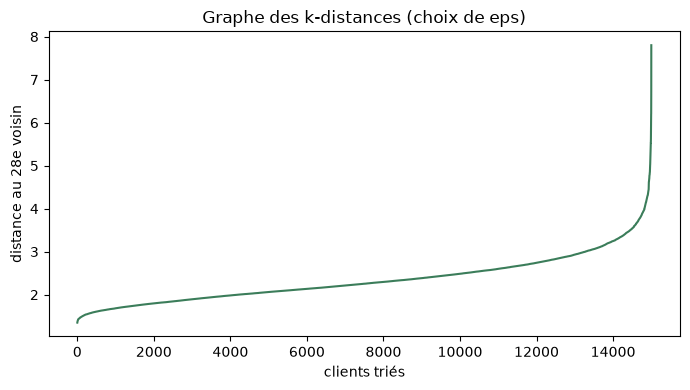

    distance
50      2.25
70      2.54
80      2.74
90      3.06
95      3.37
99      4.12


In [4]:
MIN_SAMPLES = 2 * Zc.shape[1]

nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Zc)
kdist = np.sort(nn.kneighbors(Zc)[0][:, -1])

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(kdist, color="#3b7d5a")
ax.set_xlabel("clients triés"); ax.set_ylabel(f"distance au {MIN_SAMPLES}e voisin")
ax.set_title("Graphe des k-distances (choix de eps)")
plt.tight_layout(); plt.savefig(REPORT_DIR / "dbscan_kdistance.png", dpi=120); plt.show()
print(pd.Series({p: np.percentile(kdist, p) for p in [50, 70, 80, 90, 95, 99]}).round(2).to_frame("distance"))

In [5]:
def eval_labels(Zm, labels):
    """Métriques sur les points classés (bruit = -1 exclu)."""
    mask = labels != -1
    n_cl = len(set(labels[mask]))
    res = {"n_clusters": n_cl, "bruit_%": round(100 * (~mask).mean(), 1)}
    if n_cl >= 2 and mask.sum() > n_cl:
        with config_context(working_memory=64):
            res["silhouette"] = round(silhouette_score(Zm[mask], labels[mask]), 3)
        res["davies_bouldin"] = round(davies_bouldin_score(Zm[mask], labels[mask]), 3)
        res["plus_gros_%"] = round(100 * pd.Series(labels[mask]).value_counts(normalize=True).iloc[0], 1)
    return res

rows = []
for p in [50, 60, 70, 80, 90, 95]:
    eps = float(np.percentile(kdist, p))
    t0 = time.time()
    lab = DBSCAN(eps=eps, min_samples=MIN_SAMPLES, n_jobs=-1).fit_predict(Zc)
    rows.append({"percentile": p, "eps": round(eps, 2), **eval_labels(Zc, lab), "temps_s": round(time.time() - t0, 1)})
    print(f"eps (p{p}) = {eps:.2f} fait")
db_grid = pd.DataFrame(rows).set_index("percentile")
display(db_grid)
db_grid.to_csv(REPORT_DIR / "dbscan_grille.csv")

eps (p50) = 2.25 fait
eps (p60) = 2.38 fait
eps (p70) = 2.54 fait
eps (p80) = 2.74 fait
eps (p90) = 3.06 fait
eps (p95) = 3.37 fait


,eps,n_clusters,bruit_%,temps_s,silhouette,davies_bouldin,plus_gros_%
percentile,,,,,,,
50,2.25,1,20.8,7.8,NaN,NaN,NaN
60,2.38,1,14.4,7.9,NaN,NaN,NaN
70,2.54,2,9.0,18.7,0.377,0.843,99.6
80,2.74,1,4.8,7.7,NaN,NaN,NaN
90,3.06,1,1.8,9.4,NaN,NaN,NaN
95,3.37,1,0.6,13.1,NaN,NaN,NaN


**Lecture de la grille :**
- `eps` petit → presque tout est du **bruit** (aucune zone assez dense).
- `eps` grand → tout fusionne en **un seul groupe géant** (`plus_gros_%` proche de 100).
- Sur un comportement d'achat continu, il est fréquent qu'aucun `eps` ne donne 4 groupes équilibrés : c'est un **résultat** à interpréter (les clients ne forment pas d'îlots séparés, ce que la faible silhouette de K-Means laissait déjà penser), pas un échec.

Le choix automatique ci-dessous retient, parmi les `eps` donnant 2 à 10 groupes avec au plus 30 % de bruit et un groupe dominant inférieur à 90 %, celui de meilleure silhouette. S'il n'y en a aucun, il prend le 90e percentile et le signale. Tu peux forcer une valeur dans `EPS_MANUEL`.

In [6]:
EPS_MANUEL = None   # ex. 2.8 pour forcer une valeur

ok = db_grid[(db_grid["n_clusters"].between(2, 10)) & (db_grid["bruit_%"] <= 30)]
if "plus_gros_%" in ok.columns:
    ok = ok[ok["plus_gros_%"] < 90]
if "silhouette" in ok.columns:
    ok = ok.dropna(subset=["silhouette"])

if EPS_MANUEL is not None:
    EPS = float(EPS_MANUEL); why = "valeur manuelle"
elif len(ok) and "silhouette" in ok.columns:
    best = ok["silhouette"].idxmax()
    EPS = float(ok.loc[best, "eps"]); why = "meilleure silhouette parmi les configurations acceptables"
else:
    EPS = float(np.percentile(kdist, 90)); why = "AUCUNE configuration acceptable : repli sur le 90e percentile"
print(f"eps retenu = {EPS:.2f} ({why})")

eps retenu = 3.06 (AUCUNE configuration acceptable : repli sur le 90e percentile)


## 5 — GMM : choix du nombre de composantes

Le GMM modélise les données comme un mélange de K lois normales multivariées (groupes elliptiques, contrairement aux groupes sphériques de K-Means). Le critère **BIC** (plus bas = meilleur) pénalise la complexité : il donne un avis statistique indépendant sur K. Calculé sur 30 000 clients pour limiter le temps.

k=2 ok
k=3 ok
k=4 ok
k=5 ok
k=6 ok
k=7 ok
k=8 ok


,BIC,AIC
k,,
2,1053989.0,1052003.0
3,1036812.0,1033829.0
4,969797.0,965817.0
5,964262.0,959285.0
6,961426.0,955451.0
7,887867.0,880896.0
8,885691.0,877722.0


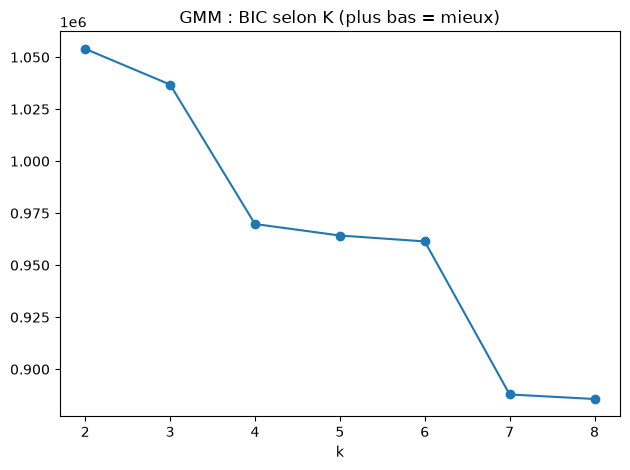

K au BIC minimal : 8 | K retenu pour la comparaison : 4


In [7]:
bic_idx = rng.choice(len(Z), size=min(30_000, len(Z)), replace=False)
Zb = Z.values[bic_idx]
bic_rows = []
for k in range(2, 9):
    g = GaussianMixture(n_components=k, covariance_type="full", n_init=1, random_state=RANDOM_STATE).fit(Zb)
    bic_rows.append({"k": k, "BIC": g.bic(Zb), "AIC": g.aic(Zb)})
    print(f"k={k} ok")
gmm_sel = pd.DataFrame(bic_rows).set_index("k")
display(gmm_sel.round(0))
gmm_sel["BIC"].plot(marker="o", title="GMM : BIC selon K (plus bas = mieux)")
plt.tight_layout(); plt.savefig(REPORT_DIR / "gmm_bic.png", dpi=120); plt.show()
print("K au BIC minimal :", int(gmm_sel["BIC"].idxmin()), "| K retenu pour la comparaison :", K)

Le BIC baisse souvent encore à K élevé quand les données sont continues : il tend à préférer beaucoup de composantes. Pour une **comparaison équitable** on garde le même K que K-Means (K = 4). Le K au BIC minimal est cité comme information complémentaire.

## 6 — Comparaison des trois modèles sur le même échantillon

Chaque modèle est (ré)entraîné sur les 15 000 clients de l'échantillon, chronométré, puis évalué avec les mêmes métriques. Pour DBSCAN, les métriques ne portent que sur les points classés (hors bruit) : à lire avec la part de bruit.

In [8]:
results, labs = {}, {}

t0 = time.time(); km = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(Zc)
labs["K-Means"] = km.labels_; t_km = time.time() - t0

t0 = time.time(); gm = GaussianMixture(n_components=K, covariance_type="full", n_init=3, random_state=RANDOM_STATE).fit(Zc)
labs["GMM"] = gm.predict(Zc); t_gm = time.time() - t0

t0 = time.time(); labs["DBSCAN"] = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES, n_jobs=-1).fit_predict(Zc); t_db = time.time() - t0

for name, t in [("K-Means", t_km), ("GMM", t_gm), ("DBSCAN", t_db)]:
    results[name] = {**eval_labels(Zc, labs[name]), "temps_s": round(t, 1)}
comp = pd.DataFrame(results).T
display(comp)

def ari(a, b):
    m = (a != -1) & (b != -1)
    return round(adjusted_rand_score(a[m], b[m]), 3)
print("\nAccord entre modèles (ARI, points classés par les deux) :")
print("  K-Means vs GMM    :", ari(labs["K-Means"], labs["GMM"]))
print("  K-Means vs DBSCAN :", ari(labs["K-Means"], labs["DBSCAN"]))
print("  GMM vs DBSCAN     :", ari(labs["GMM"], labs["DBSCAN"]))
comp.to_csv(REPORT_DIR / "comparaison_modeles.csv")

,n_clusters,bruit_%,silhouette,davies_bouldin,plus_gros_%,temps_s
K-Means,4.0,0.0,0.098,2.469,29.6,2.5
GMM,4.0,0.0,0.018,3.514,33.4,13.6
DBSCAN,1.0,1.8,NaN,NaN,NaN,9.8



Accord entre modèles (ARI, points classés par les deux) :
  K-Means vs GMM    : 0.204
  K-Means vs DBSCAN : 0.0
  GMM vs DBSCAN     : 0.0


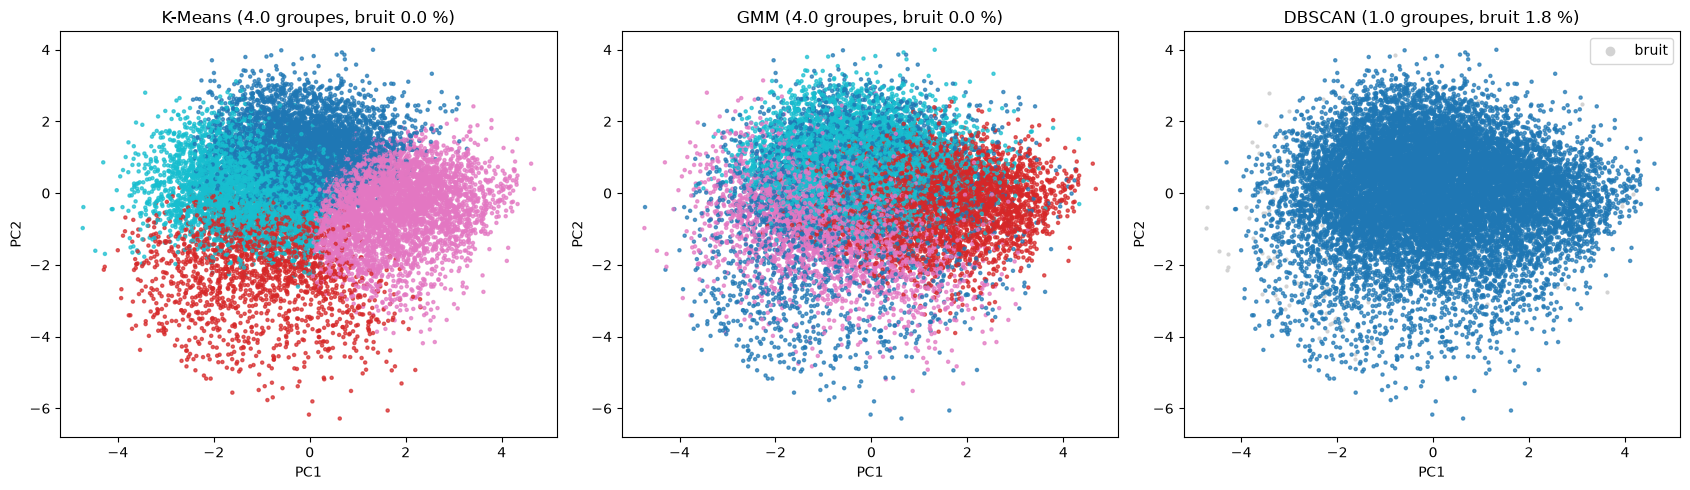

In [9]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(Z.values)
P = pca.transform(Zc)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, name in zip(axes, ["K-Means", "GMM", "DBSCAN"]):
    lab = labs[name]
    noise = lab == -1
    ax.scatter(P[noise, 0], P[noise, 1], c="lightgrey", s=4, label="bruit")
    sc = ax.scatter(P[~noise, 0], P[~noise, 1], c=lab[~noise], cmap="tab10", s=5, alpha=0.7)
    ax.set_title(f"{name} ({comp.loc[name, 'n_clusters']} groupes, bruit {comp.loc[name, 'bruit_%']} %)")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
    if noise.any(): ax.legend(loc="upper right", markerscale=3)
plt.tight_layout(); plt.savefig(REPORT_DIR / "comparaison_pca.png", dpi=120); plt.show()

## 7 — GMM sur tous les clients : confiance d'affectation et correspondance avec K-Means

Avantage propre au GMM : pour chaque client, une **probabilité** d'appartenir à chaque segment. Un client dont la probabilité maximale est faible est « entre deux segments » : cela quantifie le continuum observé. On compare ensuite les segments GMM aux segments K-Means.

In [10]:
gmm_full = GaussianMixture(n_components=K, covariance_type="full", n_init=3, random_state=RANDOM_STATE).fit(Z.values)
proba = gmm_full.predict_proba(Z.values)
seg_gmm = proba.argmax(axis=1)
conf = proba.max(axis=1)

print("Confiance moyenne d'affectation :", round(conf.mean(), 3))
print("Clients ambigus (proba max < 0,6) :", f"{(conf < 0.6).mean():.1%}")
print("\nTaille des segments GMM :")
display(pd.Series(seg_gmm).value_counts(normalize=True).sort_index().round(3).to_frame("part"))

ct = pd.crosstab(df["segment_name"], pd.Series(seg_gmm, index=df.index, name="segment_gmm"), normalize="index").round(2)
print("\nCorrespondance K-Means (lignes) -> GMM (colonnes), part de chaque segment K-Means :")
display(ct)
print("ARI K-Means vs GMM (tous les clients) :", round(adjusted_rand_score(labels_km_full, seg_gmm), 3))

Confiance moyenne d'affectation : 0.908
Clients ambigus (proba max < 0,6) : 6.4%

Taille des segments GMM :


,part
0,0.341
1,0.238
2,0.213
3,0.207



Correspondance K-Means (lignes) -> GMM (colonnes), part de chaque segment K-Means :


segment_gmm,0,1,2,3
segment_name,,,,
Segment 0,0.61,0.08,0.04,0.27
Segment 1,0.01,0.04,0.41,0.54
Segment 2,0.20,0.59,0.12,0.09
Segment 3,0.37,0.08,0.40,0.15


ARI K-Means vs GMM (tous les clients) : 0.192


In [11]:
# Profil des segments GMM (indice : 100 = moyenne globale), à comparer au profil K-Means du notebook 04
prof_gmm = feat.groupby(seg_gmm).mean()
idx_gmm = (prof_gmm / feat.mean() * 100).round(0)
idx_gmm.insert(0, "part_%", (100 * pd.Series(seg_gmm).value_counts(normalize=True).sort_index()).round(1).values)
display(idx_gmm)

zprof = Z.groupby(seg_gmm).mean()
for s in zprof.index:
    top = zprof.loc[s].sort_values(key=abs, ascending=False).head(4)
    print(f"GMM segment {s} : " + ", ".join(f"{v} ({'+' if x > 0 else '-'}{abs(x):.1f}σ)" for v, x in top.items()))
idx_gmm.to_csv(REPORT_DIR / "profil_segments_gmm.csv")

,part_%,nb_orders,mean_gap_days,weekend_share,morning_share,evening_share,avg_basket_size,reorder_ratio,organic_share,share_produce,share_dairy_eggs,share_snacks,share_beverages,share_frozen,share_pantry
0,34.1,56.0,110.0,109.0,95.0,102.0,124.0,83.0,114.0,123.0,103.0,71.0,55.0,102.0,100.0
1,23.8,218.0,71.0,100.0,98.0,99.0,119.0,137.0,122.0,110.0,111.0,86.0,79.0,97.0,92.0
2,21.3,77.0,105.0,92.0,96.0,109.0,79.0,92.0,63.0,50.0,86.0,137.0,145.0,198.0,110.0
3,20.7,60.0,112.0,94.0,114.0,89.0,61.0,93.0,90.0,102.0,97.0,127.0,152.0,0.0,98.0


GMM segment 0 : avg_basket_size (+0.4σ), nb_orders (-0.4σ), share_beverages (-0.4σ), share_produce (+0.4σ)
GMM segment 1 : nb_orders (+1.2σ), reorder_ratio (+0.7σ), mean_gap_days (-0.6σ), avg_basket_size (+0.4σ)
GMM segment 2 : share_frozen (+0.9σ), share_produce (-0.8σ), organic_share (-0.5σ), share_beverages (+0.4σ)
GMM segment 3 : share_frozen (-0.9σ), avg_basket_size (-0.8σ), nb_orders (-0.5σ), share_beverages (+0.4σ)


## 8 — Tableau de synthèse à présenter

À compléter avec **tes** résultats (cellule 6), puis à reporter dans le rapport :

| Critère | K-Means | GMM | DBSCAN |
|---|---|---|---|
| Nombre de groupes | K fixé (4) | K fixé (4) | trouvé automatiquement |
| Clients classés | 100 % | 100 % (avec probabilités) | 100 % − bruit |
| Silhouette / Davies-Bouldin | … | … | … (hors bruit) |
| Temps de calcul | … | … | … |
| Passage à l'échelle (206 000 clients) | excellent | bon | difficile (mémoire) |
| Lisibilité des profils | très bonne | bonne | dépend du résultat |
| Gère les formes non sphériques | non | oui (ellipses) | oui |
| Détecte les clients atypiques | non | partiellement (proba faible) | oui (bruit) |

**Comment conclure (à adapter aux chiffres obtenus) :**
- Si DBSCAN donne un seul gros groupe + du bruit, ou beaucoup de bruit : les clients forment un **continuum sans zones denses séparées** ; DBSCAN n'est pas adapté pour segmenter toute la base, mais il est utile pour repérer les **clients atypiques** (bruit).
- Si GMM et K-Means ont un ARI élevé et les mêmes profils : les segments sont **robustes au choix de l'algorithme** (argument fort).
- Le modèle retenu pour l'opérationnel est celui qui combine qualité des métriques, **stabilité**, **lisibilité métier** et **facilité d'industrialisation** (K-Means ou GMM, rarement DBSCAN sur ce type de données).

## 9 — Export (facultatif)

Ajoute les segments GMM, la confiance et un indicateur « atypique » (probabilité faible) à la table Gold, sans écraser le fichier d'origine.

In [12]:
out = df.copy()
out["segment_gmm"] = seg_gmm
out["gmm_confiance"] = conf.round(4)
out_path = ROOT / "data" / "gold" / "user_segments_compare.parquet"
out.reset_index().to_parquet(out_path, index=False)
print("Écrit :", out_path, f"({len(out):,} lignes)")

Écrit : d:\Users\HP\Desktop\Mastère 1 SEM 1\DEEP_LEARNING\projet_mspr_panier_vert\data\gold\user_segments_compare.parquet (206,209 lignes)
